# H4 (exploratory): is the off-resonance association larger than two smooth maps produce by chance?

In [1]:
import os
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")   # one thread per worker process
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import figs   # figs.py, next to this notebook

# Pipeline outputs (../pipeline/run_pipeline.sh): set RR_DERIV, or edit here. Needs brainsmash (pip install brainsmash).
DERIV = Path(os.environ.get("RR_DERIV", "/path/to/derivatives"))
FIGS = DERIV / "analysis" / "figures" / "stage2"
EXPL = DERIV / "analysis" / "exploratory"
METRICS = ("FA", "MD", "MK")
SCANNERS = ["Ingenia32", "Premier48", "Premier21", "Prisma64", "Prisma32"]
pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams["figure.dpi"] = 60   # inline size; saved PNGs are 300 dpi
info = figs.pair_info(DERIV)

In [2]:
import multiprocessing as mp  # noqa: E402
import time  # noqa: E402

import nibabel as nib  # noqa: E402
from brainsmash.mapgen import Base, Sampled  # noqa: E402
from scipy import sparse  # noqa: E402
from scipy.spatial import cKDTree  # noqa: E402
from scipy.spatial.distance import pdist, squareform  # noqa: E402
from scipy.stats import norm, rankdata  # noqa: E402

VARDIR = EXPL / "H4_variogram_null"
VARDIR.mkdir(parents=True, exist_ok=True)
N_NULL = int(os.environ.get("RR_N_SURROGATES", 1000))
N_EXAMPLES, N_BINS, WORKERS = 4, 10, int(os.environ.get("RR_WORKERS", 40))
KNN, DELTAS = 2000, np.array([0.02, 0.04, 0.07, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
ACF_BIN, ACF_MAX = 4.0, 100.0                       # mm
ORDER = sorted(info, key=lambda q: float(info[q]["cnr_b1000_within"]))


def nscore(v):
    """Normal scores: ranks mapped to a standard normal (the test statistic is a rank correlation)."""
    return norm.ppf((rankdata(v) - 0.5) / len(v))


def zrank(v):
    r = rankdata(v)
    return (r - r.mean()) / r.std()


class SparseSampled(Sampled):
    """brainsmash.mapgen.Sampled with two steps arranged for speed (same results up to rounding)."""

    # k-nearest-neighbour smoothing as a sparse matrix product; one matrix per neighbourhood size

    def smooth_map(self, x, k):
        if not hasattr(self, "_W"):
            self._W = {}
        if k not in self._W:
            w = self._kernel(self._D[:, :k])
            w = (w / w.sum(axis=1, keepdims=True)).astype(np.float32)
            self._W[k] = sparse.csr_matrix((w.ravel(), self._index[:, :k].ravel(), np.arange(0, w.size + 1, k)),
                                           shape=(self._nmap, self._nmap))
        return self._W[k] @ np.asarray(x, float)

    def smooth_variogram(self, u, v, return_h=False):
        # same Gaussian-weighted variogram; the weights depend only on the sampled pairs, so they are computed once
        # per surrogate and applied as a matrix product
        c = getattr(self, "_wcache", None)
        if c is None or c[0].shape != u.shape or not np.array_equal(c[0], u):
            w = np.exp(-np.square(2.68 * np.abs(u - self._h[:, None]) / self._b) / 2)
            c = self._wcache = (u, w, w.sum(axis=1))
        out = (c[1] @ v) / c[2]
        return (out, self._h) if return_h else out


def rank_acf(xyz, z, S, seed=0, n_sub=4000):
    """Autocorrelation of the rank-transformed map against distance (ACF_BIN classes), real map and surrogates."""
    rs = np.random.RandomState(seed)
    sub = rs.choice(len(z), min(n_sub, len(z)), replace=False)
    b = (pdist(xyz[sub]) // ACF_BIN).astype(int)
    nb = np.bincount(b)
    i, j = np.triu_indices(len(sub), 1)
    f = lambda v: np.bincount(b, zrank(v)[sub][i] * zrank(v)[sub][j]) / np.maximum(nb, 1)  # noqa: E731
    keep = ((np.arange(len(nb)) + 0.5) * ACF_BIN <= ACF_MAX) & (nb > 0)           # no pairs closer than the sampling
    a = np.array([f(s)[keep] for s in S])
    return (np.arange(len(nb))[keep] + 0.5) * ACF_BIN, f(z)[keep], a


_GEN = None


def _one(seed):
    s = _GEN._call_method(rs=seed)
    return np.asarray(s, np.float32).squeeze(), getattr(_GEN, "_dopt", np.nan)


def surrogates(gen, n, seed):
    """n surrogate maps from a brainsmash generator, in forked workers that share its distance arrays."""
    global _GEN
    _GEN = gen
    seeds = np.random.RandomState(seed).randint(np.iinfo(np.int32).max, size=n)
    with mp.get_context("fork").Pool(min(WORKERS, n)) as pool:
        out = pool.map(_one, seeds, chunksize=1)
    return np.stack([o[0] for o in out]), np.array([o[1] for o in out])


def variogram_pair(k, q):
    T = DERIV / "templates" / q / f"repeat-{info[q]['repeat_scanner']}"
    img = nib.load(str(T / "T_wm_2mm.nii.gz"))
    wm = np.asarray(img.dataobj) > 0
    lab = np.asarray(nib.load(str(T / "T_xtract_rois_2mm.nii.gz")).dataobj).astype(int)
    shp, vox = wm.shape, float(img.header.get_zooms()[0])
    ijk = np.array(np.nonzero(wm)).T
    cnt = np.bincount(lab[wm], minlength=lab.max() + 1)
    cent = np.stack([np.bincount(lab[wm], ijk[:, a], minlength=lab.max() + 1) for a in range(3)], 1) / np.maximum(cnt, 1)[:, None]
    rows, null_cols, acf_rows, dec, sel = [], {}, [], {}, {}
    for lv, level in (("a", "voxel"), ("b", "ROI")):
        tabs = {m: pd.read_csv(DERIV / "analysis" / "inputs" / f"h4{lv}_{q}_{m}.csv.gz") for m in METRICS}
        u = pd.concat(tabs.values()).drop_duplicates("unit").sort_values("unit")
        units, hz = u.unit.to_numpy(), u.off_hz.to_numpy()
        z = nscore(hz)
        if level == "voxel":
            xyz = np.array(np.unravel_index(units, shp), float).T * vox
            D, I = cKDTree(xyz).query(xyz, k=KNN + 1, workers=WORKERS)
            gen = SparseSampled(z, D.astype(np.float32), I.astype(np.int32), ns=500, knn=KNN, pv=100, deltas=DELTAS)
            for d in DELTAS:                                     # build the smoothing matrices before forking
                gen.smooth_map(z, int(d * KNN))
        else:
            xyz = cent[units] * vox
            gen = Base(z, squareform(pdist(xyz)), deltas=DELTAS[DELTAS >= 0.04], pv=50)
        S, dopt = surrogates(gen, N_NULL, 20261116 + 10 * k + (level == "ROI"))
        if level == "voxel":
            sel[level] = dopt                                   # neighbourhood fraction chosen per surrogate
        dist, a_real, a_sur = rank_acf(xyz, z, S[:200])
        acf_rows.append(pd.DataFrame(dict(pair=q, level=level, dist_mm=dist, real=a_real, surr_median=np.median(a_sur, 0),
                                          surr_low=np.percentile(a_sur, 2.5, 0), surr_high=np.percentile(a_sur, 97.5, 0))))
        for m, t in tabs.items():
            ix = np.searchsorted(units, t.unit.to_numpy())
            ry = zrank(t.delta.to_numpy())
            obs = float(np.mean(ry * zrank(t.off_hz.to_numpy())))
            Sm = S[:, ix]
            R = np.argsort(np.argsort(Sm, axis=1), axis=1)                       # ranks of each surrogate on these units
            nl = ((R - R.mean(1, keepdims=True)) / R.std(1, keepdims=True)) @ ry / len(ry)
            null_cols[f"{level}_{m}"] = nl
            hz_m, y0 = t.off_hz.to_numpy(), t.delta.to_numpy() - t.delta.mean()     # the same surrogates for the slope beta1
            vs = np.sort(hz_m)[R]                                                    # surrogate fields in Hz
            b1 = float(np.mean((hz_m - hz_m.mean()) * y0) / hz_m.var())              # least squares (= registered beta1)
            nb1 = (vs @ y0) / len(y0) / hz_m.var()
            null_cols[f"beta1_{level}_{m}"] = nb1
            rows.append(dict(pair=q, repeat_scanner=info[q]["repeat_scanner"], level=level, metric=m, units=len(ix),
                             observed_rho=obs, null_sd=nl.std(), null_median=np.median(nl),
                             null_low=np.percentile(nl, 2.5), null_high=np.percentile(nl, 97.5),
                             p_two_sided=(1 + np.sum(np.abs(nl) >= abs(obs))) / (1 + len(nl)),
                             off_hz_sd=hz_m.std(), beta1_per_hz=b1, beta1_null_low=np.percentile(nb1, 2.5),
                             beta1_null_high=np.percentile(nb1, 97.5),
                             beta1_p_two_sided=(1 + np.sum(np.abs(nb1) >= abs(b1))) / (1 + len(nb1))))
            if level == "voxel":                                               # decile curves, surrogate ranks -> Hz
                v = np.sort(t.off_hz.to_numpy())[R]
                bins = np.minimum((R * N_BINS) // R.shape[1], N_BINS - 1)
                dc = 100 * (t.cov_den - t.cov_nonden).to_numpy()
                dec[m] = np.stack([np.stack([np.bincount(b_, v_, N_BINS), np.bincount(b_, dc, N_BINS)], 1) /
                                   np.bincount(b_, minlength=N_BINS)[:, None] for b_, v_ in zip(bins, v)])
        if level == "voxel":                                                    # example fields in Hz, filled over WM
            _, near = cKDTree(xyz).query(ijk * vox)
            ex = np.full((1 + N_EXAMPLES,) + shp, np.nan, np.float32)
            order = np.sort(hz)
            for e, s in enumerate([None] + list(S[:N_EXAMPLES])):
                ex[e][wm] = (hz if s is None else order[np.argsort(np.argsort(s))])[near]
            np.savez_compressed(VARDIR / f"examples_{q}.npz", real=ex[0], null=ex[1:],
                                underlay=np.asarray(nib.load(str(T / "T_template0_2mm.nii.gz")).dataobj, np.float32) *
                                (np.asarray(nib.load(str(T / "T_template0_brainmask_2mm.nii.gz")).dataobj) > 0))
    np.savez_compressed(VARDIR / f"deciles_{q}.npz", **dec)
    np.savez_compressed(VARDIR / f"selected_delta_{q}.npz", **sel)
    return rows, pd.DataFrame(null_cols).assign(pair=q), pd.concat(acf_rows)


if not (VARDIR / "summary.csv").exists():                # delete summary.csv to regenerate the surrogates
    out = []
    for k, q in enumerate(ORDER):
        t0 = time.time()
        out.append(variogram_pair(k, q))
        print(f"{q}: {N_NULL} surrogates per level in {(time.time() - t0) / 60:.1f} min", flush=True)
    pd.concat([d for _, d, _ in out]).to_csv(VARDIR / "null_rho.csv.gz", index=False)
    pd.concat([a for *_, a in out]).to_csv(VARDIR / "acf.csv.gz", index=False)
    v = pd.DataFrame([r for rows, *_ in out for r in rows])
    v["outside_null_95"] = (v.observed_rho < v.null_low) | (v.observed_rho > v.null_high)
    v["beta1_outside_null_95"] = (v.beta1_per_hz < v.beta1_null_low) | (v.beta1_per_hz > v.beta1_null_high)
    v.to_csv(VARDIR / "summary.csv", index=False)
vario = pd.read_csv(VARDIR / "summary.csv")

In [3]:
t = vario.copy()
t["scanner"] = t.repeat_scanner.str.split("_").str[0]
t["Hypothesis"] = [figs.hyp_label("H4", lv, m) for lv, m in zip(t.level, t.metric)]
t["cell"] = [f"{o:+.2f} [{lo:+.2f}, {hi:+.2f}] p={p:.3f}{' *' if out else ''}"
             for o, lo, hi, p, out in zip(t.observed_rho, t.null_low, t.null_high, t.p_two_sided, t.outside_null_95)]
print(f"outside the null's central 95%: {t.outside_null_95.sum()} of {len(t)} "
      f"({(t.outside_null_95 & (t.observed_rho > 0)).sum()} with rho > 0, "
      f"{(t.outside_null_95 & (t.observed_rho < 0)).sum()} with rho < 0)")
t.pivot(index="Hypothesis", columns="scanner", values="cell")[SCANNERS].rename_axis(
    columns="observed rho [95% of null] p; * = outside")

outside the null's central 95%: 6 of 30 (2 with rho > 0, 4 with rho < 0)


observed rho [95% of null] p; * = outside,Ingenia32,Premier48,Premier21,Prisma64,Prisma32
Hypothesis,,,,,
H4a – FA voxel-wise,"+0.03 [-0.05, +0.04] p=0.245","-0.03 [-0.08, +0.08] p=0.474","-0.04 [-0.06, +0.06] p=0.196","-0.04 [-0.09, +0.10] p=0.396","-0.07 [-0.07, +0.08] p=0.070"
H4a – MD voxel-wise,"+0.05 [-0.10, +0.11] p=0.308","-0.12 [-0.20, +0.19] p=0.260","-0.02 [-0.14, +0.15] p=0.716","-0.02 [-0.14, +0.15] p=0.767","-0.05 [-0.11, +0.11] p=0.380"
H4a – MK voxel-wise,"+0.08 [-0.10, +0.10] p=0.136","-0.14 [-0.22, +0.21] p=0.203","-0.14 [-0.14, +0.15] p=0.064","-0.09 [-0.15, +0.17] p=0.241","-0.21 [-0.16, +0.17] p=0.010 *"
H4b – FA ROI-wise,"+0.07 [-0.14, +0.13] p=0.322","+0.12 [-0.10, +0.10] p=0.010 *","-0.01 [-0.15, +0.16] p=0.906","+0.01 [-0.07, +0.07] p=0.703","-0.06 [-0.09, +0.09] p=0.234"
H4b – MD ROI-wise,"+0.08 [-0.10, +0.10] p=0.127","-0.09 [-0.11, +0.11] p=0.131","-0.02 [-0.10, +0.10] p=0.752","-0.07 [-0.12, +0.13] p=0.317","+0.03 [-0.06, +0.05] p=0.275"
H4b – MK ROI-wise,"+0.15 [-0.10, +0.09] p=0.001 *","-0.10 [-0.19, +0.18] p=0.324","-0.26 [-0.15, +0.15] p=0.001 *","-0.19 [-0.17, +0.18] p=0.028 *","-0.22 [-0.16, +0.17] p=0.007 *"


In [4]:
# the registered slope beta1 (per SD of |off-resonance|) against the same surrogates
reg = pd.read_csv(DERIV / "analysis" / "results" / "results.csv")
reg = reg[reg.hypothesis == "H4"][["pair", "level", "metric", "verdict"]]
b = t.merge(reg, on=["pair", "level", "metric"])
assert len(b) == len(t)
b["cell"] = [f"{x * s:+.3f} [{lo * s:+.3f}, {hi * s:+.3f}] p={p:.3f}{' *' if o else ''}" for x, s, lo, hi, p, o in
             zip(b.beta1_per_hz, b.off_hz_sd, b.beta1_null_low, b.beta1_null_high, b.beta1_p_two_sided, b.beta1_outside_null_95)]
o = b[b.beta1_outside_null_95]
print(f"beta1 outside the null's central 95%: {len(o)} of {len(b)} ({(o.beta1_per_hz > 0).sum()} with beta1 > 0, "
      f"{(o.beta1_per_hz < 0).sum()} with beta1 < 0); of the {(b.verdict == 'supports H4').sum()} tests that support H4: "
      f"{(o.verdict == 'supports H4').sum()} (rho: {(b.outside_null_95 & (b.verdict == 'supports H4')).sum()})")
b.pivot(index="Hypothesis", columns="scanner", values="cell")[SCANNERS].rename_axis(
    columns="beta1 per SD of |off| [95% of null] p; * = outside")

beta1 outside the null's central 95%: 12 of 30 (4 with beta1 > 0, 8 with beta1 < 0); of the 5 tests that support H4: 4 (rho: 1)


beta1 per SD of |off| [95% of null] p; * = outside,Ingenia32,Premier48,Premier21,Prisma64,Prisma32
Hypothesis,,,,,
H4a – FA voxel-wise,"+0.027 [-0.030, +0.021] p=0.046 *","+0.005 [-0.036, +0.032] p=0.750","-0.012 [-0.036, +0.027] p=0.454","-0.003 [-0.032, +0.029] p=0.821","-0.006 [-0.035, +0.037] p=0.742"
H4a – MD voxel-wise,"+0.010 [-0.035, +0.029] p=0.558","-0.041 [-0.058, +0.052] p=0.169","-0.037 [-0.029, +0.028] p=0.014 *","-0.018 [-0.024, +0.028] p=0.199","-0.017 [-0.023, +0.025] p=0.167"
H4a – MK voxel-wise,"+0.047 [-0.079, +0.073] p=0.260","-0.074 [-0.135, +0.122] p=0.280","-0.158 [-0.101, +0.086] p=0.003 *","-0.088 [-0.077, +0.074] p=0.024 *","-0.121 [-0.107, +0.096] p=0.019 *"
H4b – FA ROI-wise,"+0.063 [-0.043, +0.048] p=0.004 *","+0.040 [-0.029, +0.036] p=0.026 *","+0.005 [-0.048, +0.051] p=0.860","-0.005 [-0.013, +0.014] p=0.514","-0.018 [-0.029, +0.025] p=0.198"
H4b – MD ROI-wise,"+0.029 [-0.019, +0.020] p=0.005 *","-0.026 [-0.024, +0.021] p=0.020 *","-0.005 [-0.009, +0.009] p=0.289","-0.007 [-0.013, +0.015] p=0.356","+0.011 [-0.012, +0.012] p=0.074"
H4b – MK ROI-wise,"+0.056 [-0.047, +0.059] p=0.039","-0.046 [-0.086, +0.082] p=0.326","-0.116 [-0.072, +0.059] p=0.001 *","-0.107 [-0.067, +0.054] p=0.001 *","-0.116 [-0.084, +0.053] p=0.003 *"


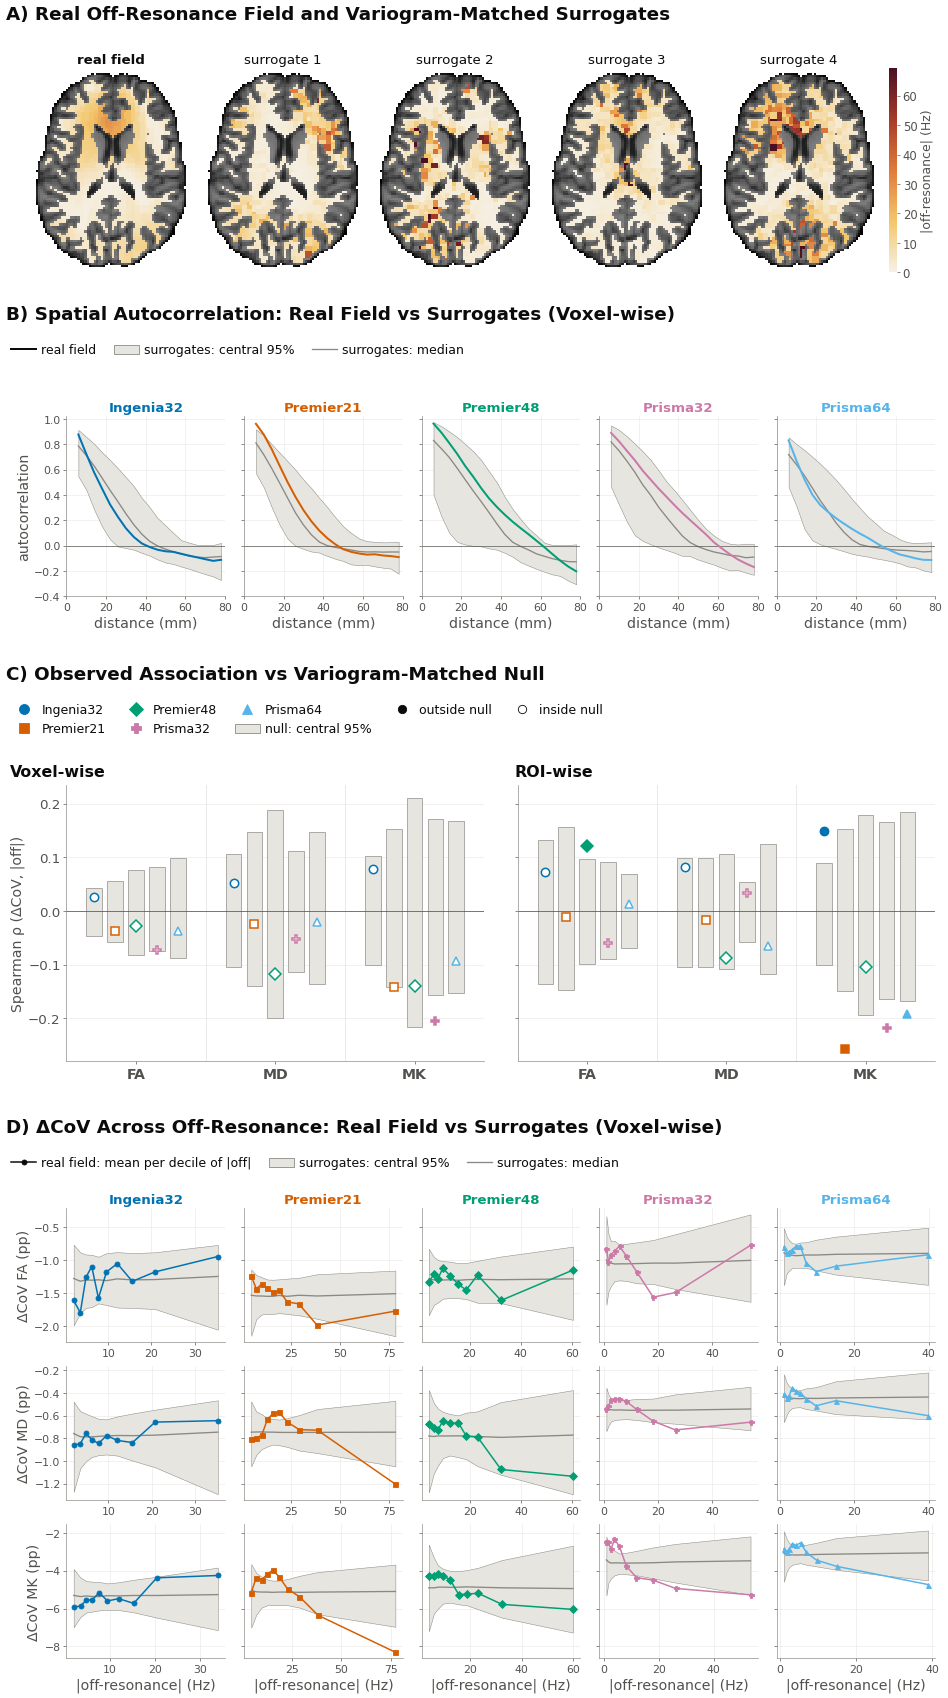

In [5]:
fig = figs.figx_h4_variogram(DERIV, METRICS, example="sub-16766", fs=16)
figs.save(fig, FIGS, "Fig9_H4_variogram_null")
plt.show()

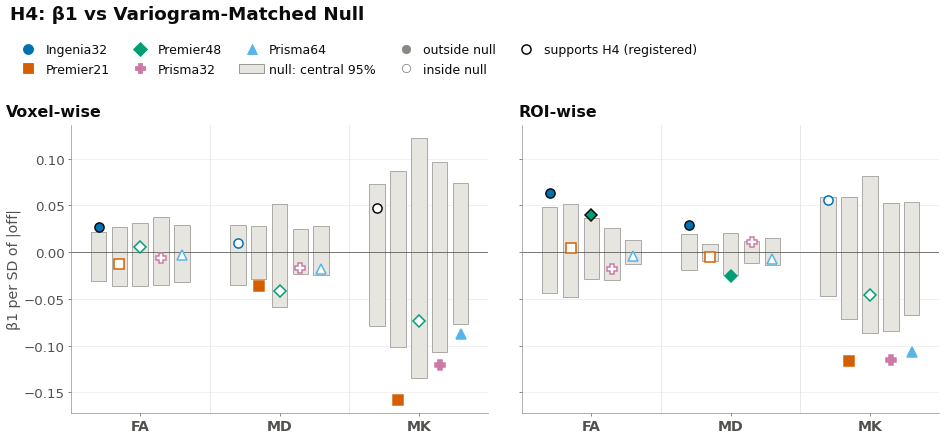

In [6]:
fig = figs.figx_h4_beta1_null(DERIV, METRICS, fs=16)
figs.save(fig, FIGS, "FigS16_H4_beta1_null")
plt.show()

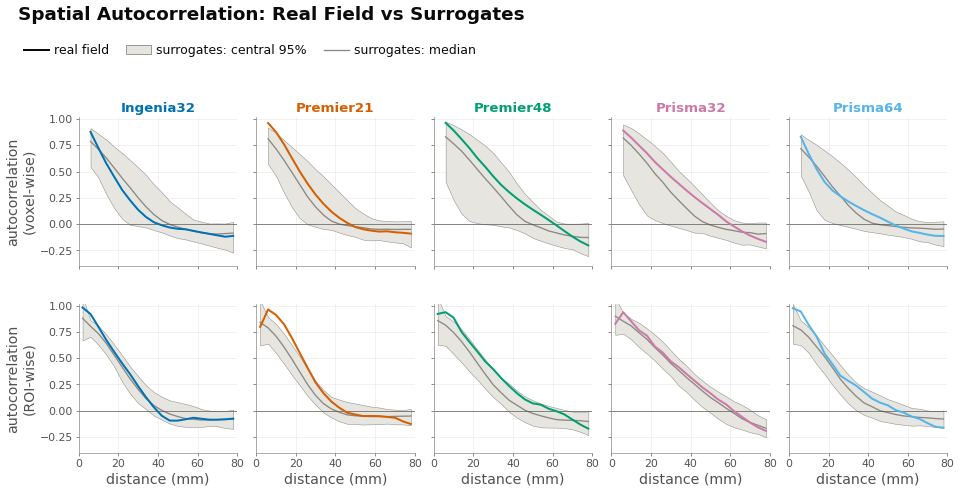

In [7]:
fig = figs.figx_h4_variogram_fit(DERIV, fs=16)
figs.save(fig, FIGS, "FigS_H4_variogram_fit")
plt.show()